In [2]:
from datasets import load_dataset

dataset = load_dataset("openpecha/OCR-Lhasakanjur", split="train")
print(dataset[0])


data/train-00001-of-00014.parquet:   0%|          | 0.00/489M [00:00<?, ?B/s]

data/train-00002-of-00014.parquet:   0%|          | 0.00/490M [00:00<?, ?B/s]

data/train-00003-of-00014.parquet:   0%|          | 0.00/498M [00:00<?, ?B/s]

data/train-00004-of-00014.parquet:   0%|          | 0.00/498M [00:00<?, ?B/s]

data/train-00005-of-00014.parquet:   0%|          | 0.00/489M [00:00<?, ?B/s]

...

data/test-00001-of-00002.parquet:   0%|          | 0.00/445M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/130109 [00:00<?, ? examples/s]

Generating eval split:   0%|          | 0/14877 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/16326 [00:00<?, ? examples/s]

{'id': '1-1-3b_0', 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1421x54 at 0x767F563BEF00>, 'label': 'བ་དེའི་ཚེ་ན། དེས་ཀྱང་དཔུང་གི་ཚོགས་ཡན་ལག་བཞི་པ། གླང་པོ་ཆེ་པའི་ཚོགས་དང༌། རྟ་པའི་ཚོགས་དང༌། ཤིང་རྟ་པའི་ཚོགས་དང༌། དཔུང་བུ་ཆུང་གི་ཚོགས་གོ་བསྐོན་ཏེ། ཡུལ་ཨང་ག་ཙམ་'}


In [10]:
ds['train'][0]

{'filename': '1-1-3b_0',
 'label': "ba de'i tshe na/_des kyang dpung gi tshogs yan lag bzhi pa/_glang po che pa'i tshogs dang*/_rta pa'i tshogs dang*/_shing rta pa'i tshogs dang*/_dpung bu chung gi tshogs go bskon te/_yul ang ga tsam "}

In [11]:
import os

os.listdir('lhasa_kanjur')[0]

'9-1-404b_line_9874_2.jpg'

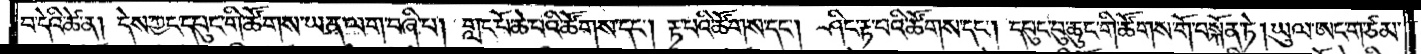

In [12]:
from PIL import Image
img = Image.open(f'lhasa_kanjur/{ds['train'][0]['filename']}.jpg')
img

In [13]:
import pyewts

converter = pyewts.pyewts()
print(converter.toUnicode(ds['train'][0]['label']))

བ་དེའི་ཚེ་ན། དེས་ཀྱང་དཔུང་གི་ཚོགས་ཡན་ལག་བཞི་པ། གླང་པོ་ཆེ་པའི་ཚོགས་དང༌། རྟ་པའི་ཚོགས་དང༌། ཤིང་རྟ་པའི་ཚོགས་དང༌། དཔུང་བུ་ཆུང་གི་ཚོགས་གོ་བསྐོན་ཏེ། ཡུལ་ཨང་ག་ཙམ་


In [14]:
def get_images(example):

    return {'id': example['filename'], 
            'image': Image.open(f'lhasa_kanjur/{example['filename']}.jpg'), 
            'label': converter.toUnicode(example['label'])
            }



In [15]:
ds = ds.map(get_images, remove_columns=['filename'])
ds

Map:   0%|          | 0/130109 [00:00<?, ? examples/s]

Map:   0%|          | 0/14877 [00:00<?, ? examples/s]

Map:   0%|          | 0/16326 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'id', 'image'],
        num_rows: 130109
    })
    eval: Dataset({
        features: ['label', 'id', 'image'],
        num_rows: 14877
    })
    test: Dataset({
        features: ['label', 'id', 'image'],
        num_rows: 16326
    })
})

In [16]:
ds['train'][0]

{'label': 'བ་དེའི་ཚེ་ན། དེས་ཀྱང་དཔུང་གི་ཚོགས་ཡན་ལག་བཞི་པ། གླང་པོ་ཆེ་པའི་ཚོགས་དང༌། རྟ་པའི་ཚོགས་དང༌། ཤིང་རྟ་པའི་ཚོགས་དང༌། དཔུང་བུ་ཆུང་གི་ཚོགས་གོ་བསྐོན་ཏེ། ཡུལ་ཨང་ག་ཙམ་',
 'id': '1-1-3b_0',
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1421x54>}

In [19]:
from datasets import DatasetDict, Dataset

dd = DatasetDict({'train': Dataset.from_dict({'id': ds['train']['id'],
                            'image': ds['train']['image'],
                            'label': ds['train']['label']
                            }),
                 'eval': Dataset.from_dict({'id': ds['eval']['id'],
                            'image': ds['eval']['image'],
                            'label': ds['eval']['label']
                            }),
                 'test': Dataset.from_dict({'id': ds['test']['id'],
                            'image': ds['test']['image'],
                            'label': ds['test']['label']
                            })
                })
dd

DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'label'],
        num_rows: 130109
    })
    eval: Dataset({
        features: ['id', 'image', 'label'],
        num_rows: 14877
    })
    test: Dataset({
        features: ['id', 'image', 'label'],
        num_rows: 16326
    })
})

In [20]:
dd['train'][0]

{'id': '1-1-3b_0',
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1421x54>,
 'label': 'བ་དེའི་ཚེ་ན། དེས་ཀྱང་དཔུང་གི་ཚོགས་ཡན་ལག་བཞི་པ། གླང་པོ་ཆེ་པའི་ཚོགས་དང༌། རྟ་པའི་ཚོགས་དང༌། ཤིང་རྟ་པའི་ཚོགས་དང༌། དཔུང་བུ་ཆུང་གི་ཚོགས་གོ་བསྐོན་ཏེ། ཡུལ་ཨང་ག་ཙམ་'}

In [21]:
dd.push_to_hub("openpecha/OCR-Lhasakanjur")

Uploading the dataset shards:   0%|          | 0/14 [00:00<?, ? shards/s]

Map:   0%|          | 0/9294 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

...

Map:   0%|          | 0/8163 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

CommitInfo(commit_url='https://huggingface.co/datasets/openpecha/OCR-Lhasakanjur/commit/00f480b6a440e3188b33ee1e15f9f1295f8a0427', commit_message='Upload dataset', commit_description='', oid='00f480b6a440e3188b33ee1e15f9f1295f8a0427', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/openpecha/OCR-Lhasakanjur', endpoint='https://huggingface.co', repo_type='dataset', repo_id='openpecha/OCR-Lhasakanjur'), pr_revision=None, pr_num=None)